# Vision Transformer on CIFAR-10

1. Train a small ViT from scratch (slides 99–101).
2. Fine-tune a pretrained ViT (slide 102).

Both models use the same train / validation / test split. The final numbers for slide 103 are the **test** accuracies printed at the end.

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(42)

In [2]:

class PatchEmbedding(nn.Module):
    def __init__(self, embed_dim=512, patch_size=16):
        super().__init__()
        self.conv = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size, bias=False)

    def forward(self, x):
        x = self.conv(x)            # (B, 512, 14, 14)
        x = x.flatten(2)            # (B, 512, 196)
        return x.transpose(1, 2)    # (B, 196, 512)

In [3]:
class PatchPositionEmbedding(nn.Module):
    def __init__(self, image_size=224, embed_dim=512, patch_size=16):
        super().__init__()
        self.patch = PatchEmbedding(embed_dim, patch_size)
        n = (image_size // patch_size) ** 2   # 196 patches

        scale = embed_dim ** -0.5
        self.cls_token = nn.Parameter(scale * torch.randn(1, 1, embed_dim))
        self.position = nn.Parameter(scale * torch.randn(1, n + 1, embed_dim))  # CLS + 196 patches

    def forward(self, x):
        patches = self.patch(x)                              # (B, 196, 512)
        cls = self.cls_token.expand(x.size(0), -1, -1)       # (B, 1, 512)
        tokens = torch.cat([cls, patches], dim=1)            # (B, 197, 512)
        return tokens + self.position                        # (B, 197, 512)

In [4]:
import time

def train_epoch(model, optimizer, criterion, train_dataloader, device, epoch=0, log_interval=50):
    model.train()
    total_acc, total_count = 0, 0
    losses = []
    start_time = time.time()

    for idx, (inputs, labels) in enumerate(train_dataloader):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        predictions = model(inputs)

        # compute loss
        loss = criterion(predictions, labels)
        losses.append(loss.item())

        # backward
        loss.backward()
        optimizer.step()
        total_acc += (predictions.argmax(1) == labels).sum().item()
        total_count += labels.size(0)
        if idx % log_interval == 0 and idx > 0:
            elapsed = time.time() - start_time
            print(
                "| epoch {:3d} | {:5d}/{:5d} batches "
                "| accuracy {:8.3f}".format(
                    epoch, idx, len(train_dataloader), total_acc / total_count
                )
            )
            total_acc, total_count = 0, 0
            start_time = time.time()

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [5]:
def evaluate_epoch(model, criterion, valid_dataloader, device):
    model.eval()
    total_acc, total_count = 0, 0
    losses = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(valid_dataloader):
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            predictions = model(inputs)

            loss = criterion(predictions, labels)
            losses.append(loss.item())

            total_acc += (predictions.argmax(1) == labels).sum().item()
            total_count += labels.size(0)

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [6]:
def train(model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device):
    train_accs, train_losses = [], []
    eval_accs, eval_losses = [], []
    best_loss_eval = float('inf')
    best_epoch = 0
    times = []
    for epoch in range(1, num_epochs+1):
        epoch_start_time = time.time()
        # Training
        train_acc, train_loss = train_epoch(model, optimizer, criterion, train_dataloader, device, epoch)
        train_accs.append(train_acc)
        train_losses.append(train_loss)

        # Evaluation on the validation split
        eval_acc, eval_loss = evaluate_epoch(model, criterion, valid_dataloader, device)
        eval_accs.append(eval_acc)
        eval_losses.append(eval_loss)

        # Save best model (lowest validation loss)
        if eval_loss < best_loss_eval:
            best_loss_eval = eval_loss
            best_epoch = epoch
            torch.save(model.state_dict(), save_model + f'/{model_name}.pt')

        times.append(time.time() - epoch_start_time)
        # Print loss, acc end epoch
        print("-" * 59)
        print(
            "| End of epoch {:3d} | Time: {:5.2f}s | Train Accuracy {:8.3f} | Train Loss {:8.3f} "
            "| Valid Accuracy {:8.3f} | Valid Loss {:8.3f} ".format(
                epoch, time.time() - epoch_start_time, train_acc, train_loss, eval_acc, eval_loss
            )
        )
        print("-" * 59)

    # Load best model
    print(f"Best epoch: {best_epoch} (valid loss {best_loss_eval:.3f})")
    model.load_state_dict(torch.load(save_model + f'/{model_name}.pt', map_location=device))
    model.eval()
    metrics = {
        'train_accuracy': train_accs,
        'train_loss': train_losses,
        'valid_accuracy': eval_accs,
        'valid_loss': eval_losses,
        'time': times,
        'best_epoch': best_epoch,
    }
    return model, metrics

In [7]:
import matplotlib.pyplot as plt

def plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses):
    epochs = list(range(1, num_epochs + 1))
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
    axs[0].plot(epochs, train_accs, label="Training")
    axs[0].plot(epochs, eval_accs, label="Validation")
    axs[1].plot(epochs, train_losses, label="Training")
    axs[1].plot(epochs, eval_losses, label="Validation")
    axs[0].set_xlabel("Epochs")
    axs[1].set_xlabel("Epochs")
    axs[0].set_ylabel("Accuracy")
    axs[1].set_ylabel("Loss")
    axs[0].legend()
    axs[1].legend()
    plt.show()

In [8]:
patchpos_embedding = PatchPositionEmbedding()
x = torch.randn(1, 3, 224, 224)

out = patchpos_embedding(x)
print(out.shape)   # torch.Size([1, 197, 512])

torch.Size([1, 197, 512])


In [9]:
class ViTTransformerEncoder(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.norm_1 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.attn = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )
        self.norm_2 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.ffn = nn.Sequential(
            nn.Linear(in_features=embed_dim, out_features=ff_dim, bias=True),
            nn.GELU(),
            nn.Linear(in_features=ff_dim, out_features=embed_dim, bias=True)
        )
        self.dropout_1 = nn.Dropout(p=dropout)
        self.dropout_2 = nn.Dropout(p=dropout)

    def forward(self, x):
        # LayerNorm before Multi-Head Attention
        norm_x1 = self.norm_1(x)
        attn_output, _ = self.attn(norm_x1, norm_x1, norm_x1)
        attn_output = self.dropout_1(attn_output)
        x = x + attn_output  # Residual connection

        # LayerNorm before Feed-Forward Network
        norm_x2 = self.norm_2(x)
        ffn_output = self.ffn(norm_x2)
        ffn_output = self.dropout_2(ffn_output)
        x = x + ffn_output  # Residual connection

        return x

In [10]:
class VisionTransformerCls(nn.Module):
    def __init__(self,
                 image_size, embed_dim, num_heads, ff_dim,
                 dropout=0.1, num_classes=10, patch_size=16, num_layers=1
        ):
        super().__init__()
        self.embd_layer = PatchPositionEmbedding(
            image_size=image_size, embed_dim=embed_dim, patch_size=patch_size
        )
        # L stacked encoder blocks (the "L x" in the ViT diagram)
        self.transformer_layers = nn.Sequential(*[
            ViTTransformerEncoder(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(num_layers)
        ])
        self.fc1 = nn.Linear(in_features=embed_dim, out_features=20)
        self.fc2 = nn.Linear(in_features=20, out_features=num_classes)
        self.dropout = nn.Dropout(p=dropout)
        self.relu = nn.ReLU()

    def forward(self, x):
        output = self.embd_layer(x)
        output = self.transformer_layers(output)
        output = output[:, 0, :]   # output state of the CLS token

        # Classification head
        output = self.dropout(output)
        output = self.fc1(output)
        output = self.relu(output)
        output = self.dropout(output)
        output = self.fc2(output)
        return output

In [11]:
image_size = 224
embed_dim = 512
num_heads = 4
ff_dim = 512
dropout = 0.1
num_layers = 1   # number of encoder blocks (L)

vit = VisionTransformerCls(image_size=image_size, embed_dim=embed_dim, num_heads=num_heads,
                           ff_dim=ff_dim, dropout=dropout, num_layers=num_layers)

In [12]:
x = torch.randn(1, 3, 224, 224)
out = vit(x)
print(out.shape)   # torch.Size([1, 10])

torch.Size([1, 10])


In [13]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from datasets import load_dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# CIFAR-10 from the Hugging Face Hub (the original cs.toronto.edu server is often unavailable).
# The images are converted once to a uint8 tensor and cached in ./data, so later runs load in about 1 second.
cache_path = './data/cifar10_uint8.pt'
if os.path.exists(cache_path):
    cifar = torch.load(cache_path)
else:
    hf = load_dataset("uoft-cs/cifar10")
    cifar = {}
    for split in ['train', 'test']:
        imgs = np.stack([np.asarray(im, dtype=np.uint8) for im in hf[split]['img']])   # (N, 32, 32, 3)
        cifar[split] = (torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous(),          # (N, 3, 32, 32)
                        torch.tensor(hf[split]['label'], dtype=torch.long))
    os.makedirs('./data', exist_ok=True)
    torch.save(cifar, cache_path)

class FastCIFARLoader:
    """Keep the 32x32 images on the device and build each batch there:
    random horizontal flip (train only) -> resize to 224x224 -> normalize with mean 0.5, std 0.5.
    Same preprocessing as the torchvision transforms, without per-image CPU work."""
    def __init__(self, images, labels, batch_size, shuffle, augment, image_size=224):
        self.images = images.to(device)
        self.labels = labels.to(device)
        self.batch_size, self.shuffle, self.augment, self.image_size = batch_size, shuffle, augment, image_size

    def __len__(self):
        return (len(self.labels) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.labels)
        order = torch.randperm(n, device=self.images.device) if self.shuffle else torch.arange(n, device=self.images.device)
        for i in range(0, n, self.batch_size):
            idx = order[i:i + self.batch_size]
            x = self.images[idx].float().div_(255)
            if self.augment:
                flip = torch.rand(len(idx), device=x.device) < 0.5
                x[flip] = x[flip].flip(-1)
            x = F.interpolate(x, size=(self.image_size, self.image_size), mode='bilinear', align_corners=False)
            yield (x - 0.5) / 0.5, self.labels[idx]

# 50,000 training images -> 45,000 train + 5,000 validation. The 10,000 test images are used only once, at the end.
train_images, train_labels = cifar['train']
test_images, test_labels = cifar['test']
perm = torch.randperm(len(train_labels), generator=torch.Generator().manual_seed(42))
val_size = 5000
val_idx, tr_idx = perm[:val_size], perm[val_size:]

def make_loaders(bs):
    return (FastCIFARLoader(train_images[tr_idx], train_labels[tr_idx], bs, shuffle=True, augment=True),
            FastCIFARLoader(train_images[val_idx], train_labels[val_idx], bs, shuffle=False, augment=False),
            FastCIFARLoader(test_images, test_labels, bs, shuffle=False, augment=False))

batch_size = 64
trainloader, valloader, testloader = make_loaders(batch_size)
print(len(tr_idx), len(val_idx), len(test_labels))   # 45000 5000 10000

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

45000 5000 10000


## 1. Train ViT from scratch

In [14]:
import torch.optim as optim
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = VisionTransformerCls(
    image_size=image_size, embed_dim=embed_dim, num_heads=num_heads,
    ff_dim=ff_dim, dropout=dropout, num_classes=10, num_layers=num_layers
)
model.to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

num_epochs = 20
save_model = './model'
os.makedirs(save_model, exist_ok=True)
model_name = 'vit_scratch'

model, metrics = train(
    model, model_name, save_model, optimizer, criterion, trainloader, valloader, num_epochs, device
)

| epoch   1 |    50/  704 batches | accuracy    0.176
| epoch   1 |   100/  704 batches | accuracy    0.194
| epoch   1 |   150/  704 batches | accuracy    0.208
| epoch   1 |   200/  704 batches | accuracy    0.226
| epoch   1 |   250/  704 batches | accuracy    0.240
| epoch   1 |   300/  704 batches | accuracy    0.250
| epoch   1 |   350/  704 batches | accuracy    0.251
| epoch   1 |   400/  704 batches | accuracy    0.268
| epoch   1 |   450/  704 batches | accuracy    0.264
| epoch   1 |   500/  704 batches | accuracy    0.282
| epoch   1 |   550/  704 batches | accuracy    0.272
| epoch   1 |   600/  704 batches | accuracy    0.285
| epoch   1 |   650/  704 batches | accuracy    0.292
| epoch   1 |   700/  704 batches | accuracy    0.307
-----------------------------------------------------------
| End of epoch   1 | Time: 44.81s | Train Accuracy    0.316 | Train Loss    1.972 | Valid Accuracy    0.319 | Valid Loss    1.789 
-----------------------------------------------------

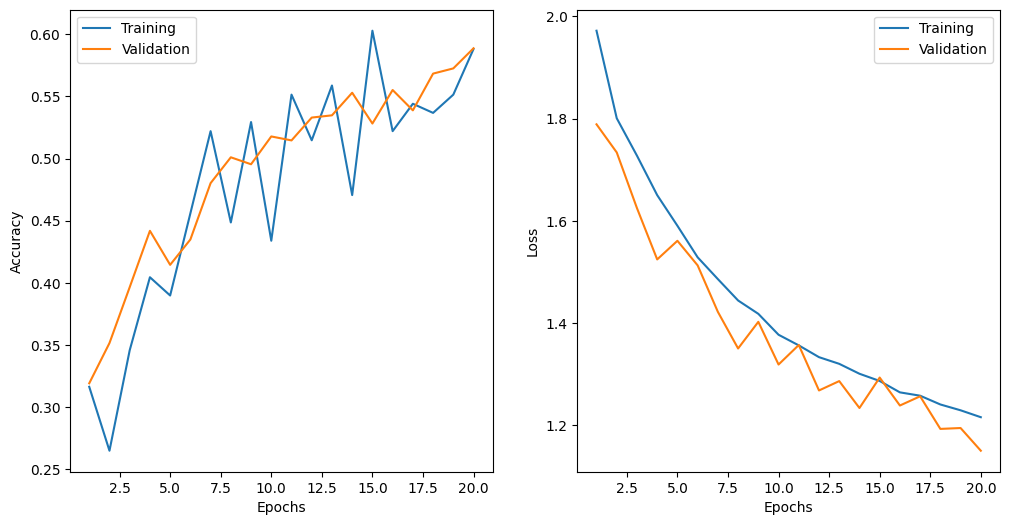

In [15]:
plot_result(
    num_epochs,
    metrics["train_accuracy"],
    metrics["valid_accuracy"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [16]:
scratch_test_acc, scratch_test_loss = evaluate_epoch(model, criterion, testloader, device)
print(f"[Scratch] Test accuracy: {scratch_test_acc:.4f} | Test loss: {scratch_test_loss:.4f}")

[Scratch] Test accuracy: 0.5751 | Test loss: 1.1747


In [17]:
import pandas as pd

df = pd.DataFrame({
    'train_accuracy': metrics["train_accuracy"],
    'valid_accuracy': metrics["valid_accuracy"],
    'train_loss': metrics["train_loss"],
    'valid_loss': metrics["valid_loss"]
})
df.to_csv('vit_training_metrics.csv', index=False)

## 2. Transfer learning: fine-tune a pretrained ViT (slide 102)

Checkpoint `google/vit-base-patch16-224-in21k` is pretrained on ImageNet-21k. Its processor uses 224×224 inputs normalized with mean 0.5 and std 0.5, the same as the transforms above, so the same data split is reused.

In [18]:
from transformers import ViTForImageClassification

checkpoint = "google/vit-base-patch16-224-in21k"

class PretrainedViT(nn.Module):
    """Return logits only, so the train/evaluate functions above can be reused."""
    def __init__(self, checkpoint, num_labels=10):
        super().__init__()
        self.vit = ViTForImageClassification.from_pretrained(
            checkpoint, num_labels=num_labels, ignore_mismatched_sizes=True)

    def forward(self, x):
        return self.vit(pixel_values=x).logits

ft_batch_size = 32   # ViT-Base is much larger than the scratch model
ft_trainloader, ft_valloader, ft_testloader = make_loaders(ft_batch_size)

ft_model = PretrainedViT(checkpoint).to(device)
ft_optimizer = torch.optim.AdamW(ft_model.parameters(), lr=2e-5, weight_decay=0.01)
ft_epochs = 3

ft_model, ft_metrics = train(
    ft_model, 'vit_finetune', save_model, ft_optimizer, criterion,
    ft_trainloader, ft_valloader, ft_epochs, device
)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


| epoch   1 |    50/ 1407 batches | accuracy    0.537
| epoch   1 |   100/ 1407 batches | accuracy    0.876
| epoch   1 |   150/ 1407 batches | accuracy    0.941
| epoch   1 |   200/ 1407 batches | accuracy    0.950
| epoch   1 |   250/ 1407 batches | accuracy    0.953
| epoch   1 |   300/ 1407 batches | accuracy    0.953
| epoch   1 |   350/ 1407 batches | accuracy    0.966
| epoch   1 |   400/ 1407 batches | accuracy    0.971
| epoch   1 |   450/ 1407 batches | accuracy    0.966
| epoch   1 |   500/ 1407 batches | accuracy    0.975
| epoch   1 |   550/ 1407 batches | accuracy    0.977
| epoch   1 |   600/ 1407 batches | accuracy    0.979
| epoch   1 |   650/ 1407 batches | accuracy    0.972
| epoch   1 |   700/ 1407 batches | accuracy    0.978
| epoch   1 |   750/ 1407 batches | accuracy    0.971
| epoch   1 |   800/ 1407 batches | accuracy    0.979
| epoch   1 |   850/ 1407 batches | accuracy    0.971
| epoch   1 |   900/ 1407 batches | accuracy    0.978
| epoch   1 |   950/ 1407 ba

In [19]:
ft_test_acc, ft_test_loss = evaluate_epoch(ft_model, criterion, ft_testloader, device)
print(f"[Fine-tune] Test accuracy: {ft_test_acc:.4f} | Test loss: {ft_test_loss:.4f}")

[Fine-tune] Test accuracy: 0.9802 | Test loss: 0.0736


## Summary for slide 103

In [20]:
summary = pd.DataFrame({
    'Setting': ['Train from scratch', 'Transfer learning'],
    'Model': [f'ViT, {num_layers} encoder layer(s), D={embed_dim}', checkpoint],
    'Epochs': [num_epochs, ft_epochs],
    'Best epoch (val loss)': [metrics['best_epoch'], ft_metrics['best_epoch']],
    'Test accuracy': [round(scratch_test_acc * 100, 2), round(ft_test_acc * 100, 2)],
})
summary.to_csv('vit_cifar10_summary.csv', index=False)
summary

,Setting,Model,Epochs,Best epoch (val loss),Test accuracy
0,Train from scratch,"ViT, 1 encoder layer(s), D=512",20,20,57.51
1,Transfer learning,google/vit-base-patch16-224-in21k,3,3,98.02
